# EEG Denoising

1. Notch filter with (50Hz)60Hz and bandpass filter with 0.5(-1)-30Hz(-50Hz) → this removes powerline noise and generally removes all frequencies that are unwanted in our data (This is done before the segmentation because of the 5s break in between)
2. Remove Artificats with ICA
3. Remove extremely high amplitudes with Amplitude based epoch rejection
4. Normalize data by applying a z-transform
5. Visual inspection


## 0. Load the data

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
PATH_TO_DATA = "../../data/eeg_data_v2_denoised"

In [4]:
df = pd.read_pickle(f"{PATH_TO_DATA}/pickle/000.pkl")
df

,genre,EEG_Ch1,EEG_Ch2,EEG_Ch3,EEG_Ch4,EEG_Ch5,EEG_Ch6,EEG_Ch7,EEG_Ch8
Song0,disco,"[18.48393027670971, 20.027689926464983, 20.482...","[-13.51666187779251, -13.857798622903388, -18....","[-0.10227597845524126, -0.13154949008557232, -...","[-4.92209331083061, -7.111761383940802, -9.955...","[4.411080414822213, 4.6027266092446055, 3.5273...","[11.371406975858509, 13.21464156505689, 12.613...","[7.932103565930662, 6.30653642360734, 3.876842...","[49.80931501013167, 47.630089555286645, 42.368..."
Song1,rock,"[-3.7793920486069394, -1.9944456174913523, -1....","[-60.47251631220662, -51.26739245414575, -44.4...","[0.028466880427783833, 0.046042881882525845, 0...","[-8.260937151334792, -8.627691068446115, -8.08...","[7.791567537761781, 10.16953691490517, 11.0350...","[-20.531270043673643, -10.941525018652156, -2....","[-0.04247486139073063, 1.0479075229761294, 1.5...","[-58.45080108026531, -44.91459257396093, -35.4..."
Song2,hiphop,"[10.80762940719157, 9.3430062844443, 7.2410381...","[-15.190608073404336, -16.013115386123403, -17...","[-0.015947415218589504, -0.019252462856113914,...","[6.320548697661688, 6.903332220769156, 7.40365...","[8.451008455665956, 7.92281890086848, 7.006182...","[5.876525936858776, 0.7265801095468712, -4.365...","[3.7561330056165136, 1.260843880830687, -0.846...","[-40.61839692914636, -44.0907000255595, -47.28..."
Song3,reggae,"[-1.4161758664527735, -1.8206100076051426, -0....","[12.35473180503862, 14.92082884890057, 18.8837...","[-0.10559007493971666, -0.16974166972420618, -...","[7.178331440623355, 6.183774917535679, 5.45097...","[2.6488518030046326, 1.415705084813502, 1.5414...","[-2.057133110808917, -1.3821812296582, -1.2620...","[3.0217630109478213, 2.526992441194343, 3.1750...","[30.994208732213114, 34.41190524974773, 38.677..."
Song4,pop,"[-8.585198507197488, -9.52892265233038, -10.54...","[10.51999154439331, 8.720001380320989, 8.42403...","[0.02729722405394812, 0.01394544550310253, -0....","[-4.926774349581876, -5.887115003299062, -7.46...","[-3.4240582978007628, -6.432746444415476, -9.2...","[-11.310915362285586, -16.53706171169682, -19....","[-6.355374315230547, -9.508603425561795, -12.0...","[46.15623318675215, 41.17734039824606, 37.3636..."
Song5,reggae,"[6.30066244421455, 9.348487980344885, 13.13939...","[8.377559409134856, 12.751941172687435, 17.450...","[0.09628613491345078, 0.12457545016836012, 0.1...","[3.473713788048567, 5.897491257169944, 8.72266...","[-0.6511484098099064, 3.3398461922571507, 7.51...","[-5.211181015700445, -1.3122328301338988, 4.88...","[3.1992042576135713, 5.898350484841217, 8.9674...","[-19.747072236598857, -10.496895476112122, 0.4..."
Song6,jazz,"[1.3097589942032042, 0.30377593316832513, -2.0...","[-26.435912825739315, -38.40845092097116, -51....","[0.038542133080499474, 0.043559670973843785, 0...","[-12.32596728355174, -14.207605757603007, -16....","[2.3100937148915897, 3.422598549329125, 2.5147...","[4.365991297886046, 1.443461278532187, -3.2658...","[5.274664599026522, 3.8365997309326745, 1.2750...","[103.98323175284466, 95.05311354182965, 85.364..."
Song7,disco,"[23.334239113646387, 21.38971102639681, 19.089...","[12.374343670195987, 15.840121950442153, 14.32...","[0.04824857713754218, 0.08715047587059017, 0.1...","[5.290929224149135, 5.305056775609511, 5.02364...","[11.068365083562743, 9.528215854027643, 6.3781...","[-5.8913403949982435, -9.728691749113372, -15....","[-1.6635642702041833, -2.3883152953400524, -3....","[33.49972970530851, 31.632187583135575, 31.377..."
Song8,country,"[4.702718630933859, 7.87108354841022, 10.33922...","[-6.7355662091634505, -6.688307596682926, -2.3...","[0.20735177869191618, 0.22490865497663182, 0.2...","[9.901291974210274, 11.431369669961521, 12.602...","[1.1583828547586394, 4.169912020149115, 6.5121...","[-19.36046169202956, -15.584237856793578, -10....","[6.454550272084126, 8.228330189327192, 9.69727...","[29.195330737242987, 26.604916615730808, 26.99..."
Song9,jazz,"[3.6445921792980673, 5.607801756292357, 6.0317...","[69.73777465

In [5]:
# Check whether the shape seems right
len(df.loc["Song0", "EEG_Ch1"])

7733

In [6]:
# For frequency filtering, all signal data has to be concatanated since we have to look at the whole session
# we therefore need to concatenate all arrays of each channel and store in a list, where each segment starts/ends

def get_concatentated_channel_data(channel_name):
  column = df[channel_name] # get the channel
  ret = []
  offsets = []
  for i in range(len(column)):
    arr = column.iloc[i]
    ret.extend(arr)
    offsets.append(len(arr))
  return ret, offsets



In [7]:
offset_accumulated_list = []
channel_data_list = []
for i in range(1, 9, 1):
  concatenated_channel_data, offsets = get_concatentated_channel_data(f"EEG_Ch{i}")
  channel_data_list.append(concatenated_channel_data)
  offset_accumulated_list.append(offsets)

In [8]:
print(np.shape(channel_data_list))

(8, 376819)


In [9]:
channel_data_list_np = np.array(channel_data_list)

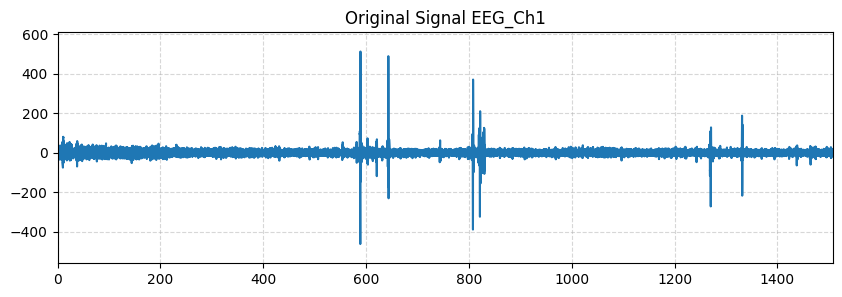

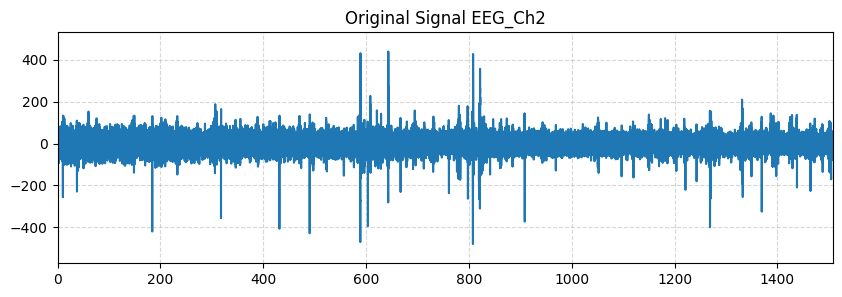

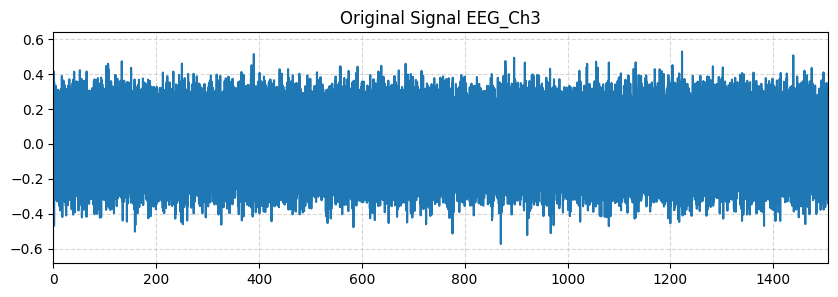

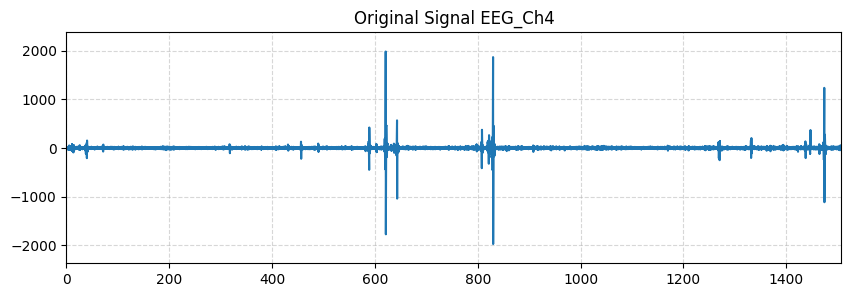

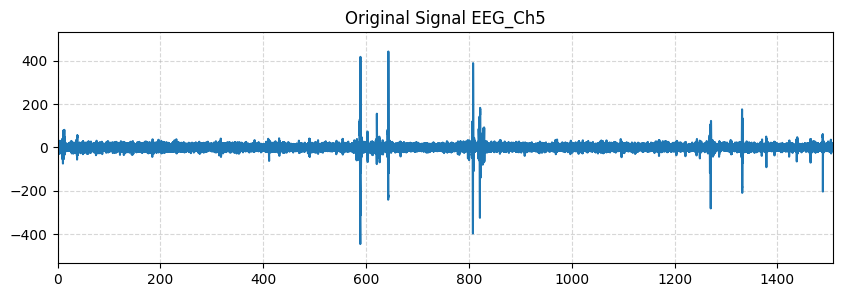

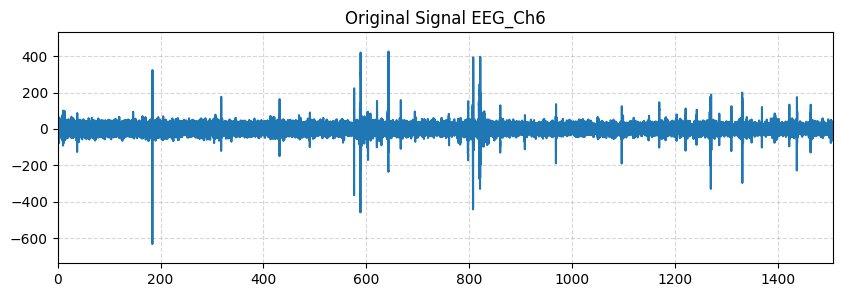

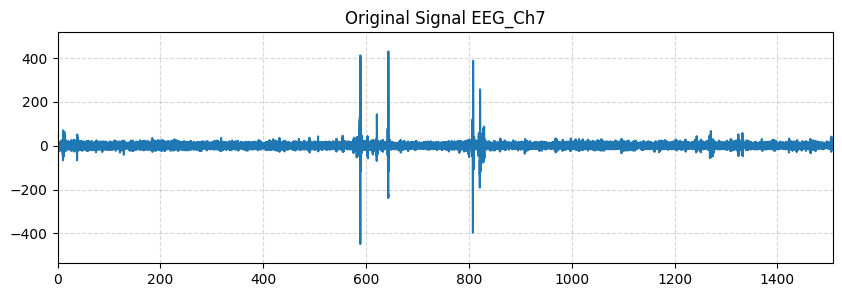

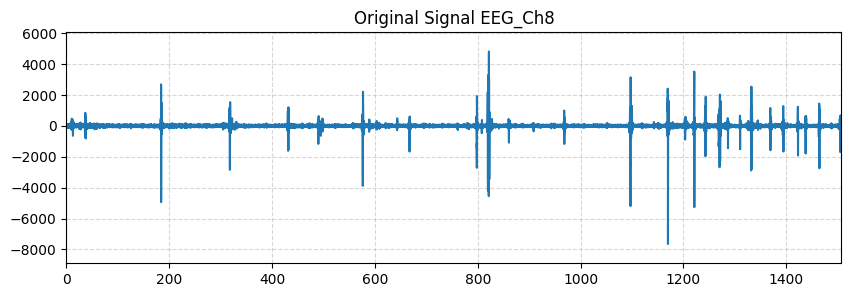

In [10]:
# visualize channels
sample_rate = 250
for i in range (channel_data_list_np.shape[0]):
  times = np.arange(len(channel_data_list_np[i]))/sample_rate
  fig, ax1 = plt.subplots(1, 1, figsize=(10, 3))
  ax1.plot(times, channel_data_list_np[i])
  ax1.set_title(f"Original Signal EEG_Ch{i+1}")
  ax1.margins(0, .1)
  ax1.grid(alpha=.5, ls='--')
  plt.show()